# MLP با ρ = 0.99 (Colored MNIST)

**تغییرات نسبت به نوت‌بوک CNN:** مدل یک **MLP بدون کانولوشن** است (ورودی تخت‌شده 3×28×28 ← 256 نورون ← 10) و `RHO_TRAIN = 0.99` در آموزش، اعتبارسنجی و تست ID. مجموعه‌های OOD همان‌اند (OOD-1: ρ=0.5 و OOD-2: ρ=0.1). بقیه (پنج روش کاهش سوگیری، آزمون‌های تشخیص نشانه، جدول‌ها) بدون تغییر است.

**نکات مهم:**
1. تعداد پارامترهای واقعی MLP برابر **604,938** است (نه ۶۰۴٬۱۷۰ که در طرح آمده بود)؛ سلول مدل مقدار واقعی را چاپ می‌کند. همچنین تعداد پارامتر CNN سه‌لایه اصلی **390,986** است، نه ۶۲۰٬۸۱۰.
2. اعداد «انتظار از نتایج» در طرح (مثلاً افت ۴۰ تا ۶۰ واحد) فرضیه‌اند، نه نتیجه. MLP با ۲۵۶ نورون روی MNIST به‌راحتی شکل رقم را یاد می‌گیرد و رنگ فقط یک بیت اطلاعات است؛ پس ممکن است افت بسیار کوچک‌تر از انتظار باشد. هر عددی که اجرا بدهد همان گزارش می‌شود و نتیجه «افت کم» هم یک یافته معتبر است.
3. Grad-CAM برای MLP تعریف‌پذیر نیست (لایه کانولوشن ندارد)؛ فقط Saliency (Gradient×Input و گرادیان کانال‌های R و G) رسم می‌شود.
4. در گزارش همه آزمایش‌ها (CNN و MLP، ρ=0.9 و ρ=0.99) را بیاورید و ترتیب و دلیل انجام آن‌ها را بنویسید؛ گزارش فقط نسخه‌ای که به افت دلخواه رسید گزینشی است.
5. برای نمودار مقایسه CNN و MLP، `results.json` نسخه CNN را در Colab آپلود کنید (مسیر در سلول مقایسه).

**اجرا:** Colab، Runtime → GPU، Run all (MLP سریع‌تر از CNN است؛ حدود ۱۵ تا ۳۰ دقیقه).

In [1]:
import os, json, time, math, random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets
import matplotlib.pyplot as plt
import pandas as pd

# ---------------- تنظیمات کلی ----------------
QUICK_TEST = False          # True → تست سریع (۲ epoch، یک seed) فقط برای اطمینان از اجرای بدون خطا
SEEDS      = [0] if QUICK_TEST else [0, 1, 2]
EPOCHS     = 2 if QUICK_TEST else 20
RHO_TRAIN  = 0.99         # همبستگی رنگ–شکل در آموزش/اعتبارسنجی/تست ID
BATCH      = 64
LR         = 1e-3

# هایپرپارامترهای روش‌های کاهش سوگیری (از پیش تعیین شده؛ روی داده OOD تنظیم نشده‌اند)
AUG_FRAC    = 0.10          # روش ۱: نسبت نمونه‌های بدون سوگیری اضافه‌شده (ρ=0.5)
DRO_ETA     = 0.01          # روش ۳: نرخ به‌روزرسانی وزن گروه‌ها (η_q)
GCE_Q       = 0.7           # روش ۴: پارامتر q در Generalized Cross Entropy
EMA_ALPHA   = 0.7           # روش ۴: ضریب EMA برای خطای هر نمونه
IRM_LAMBDA  = 1e4           # روش ۵: وزن جریمه IRM بعد از دوره گرم‌کردن
IRM_ANNEAL  = 1 if QUICK_TEST else 5   # روش ۵: تعداد epochهای اولیه با λ=1

OUT = "results_mlp_rho99"
os.makedirs(OUT, exist_ok=True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE, "| torch", torch.__version__)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s)

device: cuda | torch 2.11.0+cu130


## ۱. ساخت Colored MNIST

100%|██████████| 9.91M/9.91M [00:00<00:00, 18.2MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 493kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.62MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 13.0MB/s]


set         N  fraction(color aligned with shape)
train   50000  0.990
val     10000  0.990
id      10000  0.991
ood1    10000  0.506
ood2    10000  0.104


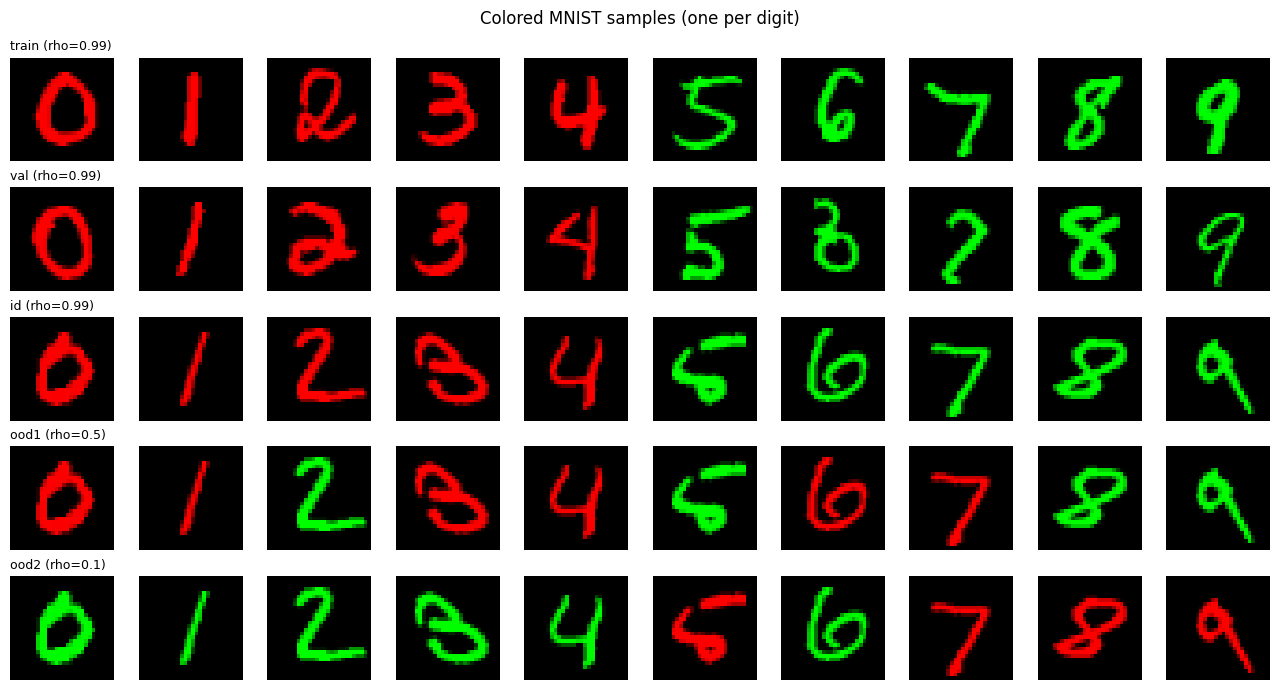

In [2]:
# ---------------- ساخت Colored MNIST ----------------
mn_tr = datasets.MNIST('./data', train=True,  download=True)
mn_te = datasets.MNIST('./data', train=False, download=True)
G_tr = mn_tr.data.numpy().astype(np.float32) / 255.0      # (60000, 28, 28)
Y_tr = mn_tr.targets.numpy().astype(np.int64)
G_te = mn_te.data.numpy().astype(np.float32) / 255.0      # (10000, 28, 28)
Y_te = mn_te.targets.numpy().astype(np.int64)

def make_colors(y, rho, seed):
    """رنگ هر نمونه: 0=قرمز، 1=سبز.
    ارقام 0-4 با احتمال rho قرمز (و در غیر این صورت سبز)، ارقام 5-9 با احتمال rho سبز."""
    rng  = np.random.RandomState(seed)
    base = (y >= 5).astype(np.int64)                 # رنگ «هم‌جهت» با شکل
    keep = rng.rand(len(y)) < rho
    return np.where(keep, base, 1 - base)

class CData:
    """مجموعه داده روی GPU: تصویر RGB، برچسب، رنگ، نیمه‌ی کلاس و گروه (رنگ×نیمه‌ی کلاس)."""
    def __init__(self, gray, y, color):
        n   = len(y)
        rgb = np.zeros((n, 3, 28, 28), np.float32)
        rgb[np.arange(n), color] = gray              # کانال 0=R، 1=G
        self.x = torch.from_numpy(rgb).to(DEVICE)
        self.y = torch.from_numpy(y).long().to(DEVICE)
        self.c = torch.from_numpy(color).long().to(DEVICE)
        self.half    = (self.y >= 5).long()          # 0: ارقام 0-4 ، 1: ارقام 5-9
        self.g       = self.c * 2 + self.half        # 0:قرمز/0-4  1:قرمز/5-9  2:سبز/0-4  3:سبز/5-9
        self.aligned = (self.c == self.half)         # رنگ هم‌جهت با شکل؟
    def __len__(self):
        return len(self.y)

def make_cmnist(gray, y, rho, seed):
    return CData(gray, y, make_colors(y, rho, seed))

# تقسیم ارقام: آموزش/اعتبارسنجی از train، و همه ۱۰٬۰۰۰ رقم test برای سه مجموعه تست
perm   = np.random.RandomState(42).permutation(len(G_tr))
tr_idx = perm[:50000]
va_idx = perm[50000:]

S = {
    'train': make_cmnist(G_tr[tr_idx], Y_tr[tr_idx], RHO_TRAIN, 42),
    'val':   make_cmnist(G_tr[va_idx], Y_tr[va_idx], RHO_TRAIN, 43),
    'id':    make_cmnist(G_te, Y_te, RHO_TRAIN, 44),
    'ood1':  make_cmnist(G_te, Y_te, 0.5, 45),
    'ood2':  make_cmnist(G_te, Y_te, 0.1, 46),
}
assert len(set(tr_idx) & set(va_idx)) == 0            # بدون نشت بین آموزش و اعتبارسنجی

SET_INFO = {   # برای جدول ۱
    'train': ('آموزش', RHO_TRAIN), 'val': ('اعتبارسنجی', RHO_TRAIN), 'id': ('تست ID', RHO_TRAIN),
    'ood1': ('تست OOD-1 (بدون سوگیری)', 0.5), 'ood2': ('تست OOD-2 (معکوس)', 0.1)}
print(f"{'set':6s} {'N':>6s}  fraction(color aligned with shape)")
for k, d in S.items():
    print(f"{k:6s} {len(d):6d}  {d.aligned.float().mean().item():.3f}")

# ---------------- نمونه تصاویر ----------------
fig, axes = plt.subplots(5, 10, figsize=(13, 7))
for r, (k, d) in enumerate(S.items()):
    for j in range(10):
        i = torch.nonzero(d.y == j)[0, 0].item()
        axes[r, j].imshow(d.x[i].permute(1, 2, 0).cpu().numpy()); axes[r, j].axis('off')
    axes[r, 0].set_title(f"{k} (rho={SET_INFO[k][1]})", loc='left', fontsize=9)
plt.suptitle("Colored MNIST samples (one per digit)"); plt.tight_layout()
plt.savefig(f"{OUT}/fig0_dataset_samples.png", dpi=150); plt.show()

## ۲. مدل (MLP) و ابزارها

In [3]:
# ---------------- مدل و ابزارهای ارزیابی ----------------
class MLP(nn.Module):
    """MLP بدون کانولوشن: ورودی تخت‌شده 3×28×28 → 256 → 10 (features/head ندارد)."""
    def __init__(self, hidden=256, dropout=0.2):
        super().__init__()
        self.fc1 = nn.Linear(3 * 28 * 28, hidden)
        self.fc2 = nn.Linear(hidden, 10)
        self.dropout = nn.Dropout(dropout)
    def forward(self, x):
        x = x.flatten(1)
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        return self.fc2(x)

Net = MLP     # نام مدل مورد استفاده در توابع آموزش

# تست سریع مدل
_t = Net().to(DEVICE)
assert _t(torch.randn(4, 3, 28, 28, device=DEVICE)).shape == (4, 10)
print(f"Total parameters: {sum(p.numel() for p in _t.parameters()):,}")   # باید 604,938 باشد
del _t

@torch.no_grad()
def predict(model, x, bs=5000):
    model.eval()
    return torch.cat([model(x[i:i+bs]).argmax(1) for i in range(0, len(x), bs)])

@torch.no_grad()
def eval_loss_acc(model, d, bs=5000):
    model.eval(); L, C = 0.0, 0
    for i in range(0, len(d), bs):
        lo, y = model(d.x[i:i+bs]), d.y[i:i+bs]
        L += F.cross_entropy(lo, y, reduction='sum').item()
        C += (lo.argmax(1) == y).sum().item()
    return L / len(d), C / len(d)

def new_hist():
    return {k: [] for k in ['obj', 'train_loss', 'train_acc', 'val_loss', 'val_acc', 'ood1_acc', 'ood2_acc']}

def log_epoch(h, model, obj, tag, ep):
    """ثبت منحنی‌ها روی مجموعه آموزش استاندارد (ρ=0.9) و اعتبارسنجی.
    دقت OOD فقط برای رسم پویایی یادگیری ثبت می‌شود و هرگز برای انتخاب مدل/هایپرپارامتر استفاده نمی‌شود."""
    tl, ta = eval_loss_acc(model, S['train']); vl, va = eval_loss_acc(model, S['val'])
    h['obj'].append(float(obj)); h['train_loss'].append(tl); h['train_acc'].append(ta)
    h['val_loss'].append(vl);    h['val_acc'].append(va)
    h['ood1_acc'].append(eval_loss_acc(model, S['ood1'])[1])
    h['ood2_acc'].append(eval_loss_acc(model, S['ood2'])[1])
    if (ep + 1) % 5 == 0 or ep == 0:
        print(f"  [{tag}] epoch {ep+1:2d}  obj={obj:.4f}  train_acc={ta:.4f}  val_acc={va:.4f}  "
              f"ood1={h['ood1_acc'][-1]:.4f}  ood2={h['ood2_acc'][-1]:.4f}")

def final_metrics(model):
    m = {k: eval_loss_acc(model, S[k])[1] for k in ['train', 'val', 'id', 'ood1', 'ood2']}
    d = S['id']; ok = (predict(model, d.x) == d.y)
    m['id_aligned']  = ok[d.aligned].float().mean().item()     # رنگ هم‌جهت با شکل
    m['id_conflict'] = ok[~d.aligned].float().mean().item()    # رنگ مخالف شکل
    return m

RES, HIST, MODELS, CUE = {}, {}, {}, {}     # نتایج: RES[method][seed] ...

def register(method, seed, model, hist):
    RES.setdefault(method, {})[seed]   = final_metrics(model)
    HIST.setdefault(method, {})[seed]  = hist
    MODELS.setdefault(method, {})[seed] = model
    r = RES[method][seed]
    print(f"==> {method} seed={seed}: ID={r['id']:.4f} OOD1={r['ood1']:.4f} OOD2={r['ood2']:.4f}")

def save_results():
    cfg = dict(EPOCHS=EPOCHS, BATCH=BATCH, LR=LR, SEEDS=SEEDS, AUG_FRAC=AUG_FRAC, DRO_ETA=DRO_ETA,
               GCE_Q=GCE_Q, EMA_ALPHA=EMA_ALPHA, IRM_LAMBDA=IRM_LAMBDA, IRM_ANNEAL=IRM_ANNEAL, RHO_TRAIN=RHO_TRAIN, ARCH='MLP',
               N_TRAIN=len(S['train']), DEVICE=DEVICE, QUICK_TEST=QUICK_TEST)
    with open(f"{OUT}/results.json", "w", encoding="utf-8") as f:
        json.dump(dict(cfg=cfg, RES=RES, CUE=CUE, HIST=HIST), f, ensure_ascii=False)

Total parameters: 604,938


## وظیفه ۱: آموزش مدل پایه

  [Baseline] epoch  1  obj=0.2385  train_acc=0.9658  val_acc=0.9587  ood1=0.6002  ood2=0.2960
  [Baseline] epoch  5  obj=0.0426  train_acc=0.9922  val_acc=0.9787  ood1=0.8171  ood2=0.6845
  [Baseline] epoch 10  obj=0.0156  train_acc=0.9970  val_acc=0.9822  ood1=0.8357  ood2=0.7144
  [Baseline] epoch 15  obj=0.0091  train_acc=0.9994  val_acc=0.9855  ood1=0.8445  ood2=0.7344
  [Baseline] epoch 20  obj=0.0072  train_acc=0.9995  val_acc=0.9847  ood1=0.8323  ood2=0.7098
==> Baseline seed=0: ID=0.9850 OOD1=0.8323 OOD2=0.7098
  [Baseline] epoch  1  obj=0.2345  train_acc=0.9656  val_acc=0.9594  ood1=0.6161  ood2=0.3318
  [Baseline] epoch  5  obj=0.0419  train_acc=0.9921  val_acc=0.9791  ood1=0.7825  ood2=0.6273
  [Baseline] epoch 10  obj=0.0173  train_acc=0.9981  val_acc=0.9836  ood1=0.8291  ood2=0.7083
  [Baseline] epoch 15  obj=0.0099  train_acc=0.9995  val_acc=0.9848  ood1=0.8417  ood2=0.7270
  [Baseline] epoch 20  obj=0.0068  train_acc=0.9993  val_acc=0.9822  ood1=0.8446  ood2=0.7302
==> B

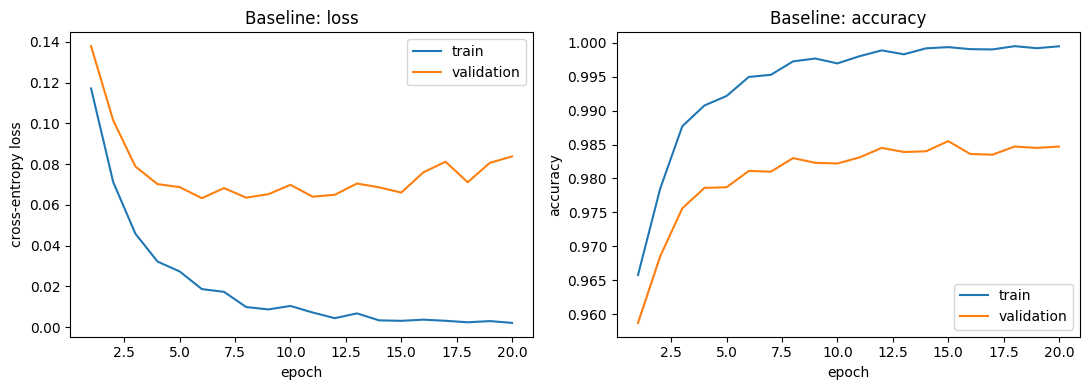

ID accuracy (mean over seeds): 98.55%


In [4]:
# ---------------- وظیفه ۱: آموزش مدل پایه ----------------
def fit_erm(tr, seed, weights=None, sample_w=None, epochs=EPOCHS, tag='ERM'):
    """آموزش استاندارد (ERM). اگر weights داده شود، خطای هر نمونه در وزنش ضرب می‌شود."""
    set_seed(seed)
    model = Net().to(DEVICE)
    opt   = torch.optim.Adam(model.parameters(), lr=LR)
    h, N  = new_hist(), len(tr)
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(N, device=DEVICE) if sample_w is None else torch.multinomial(sample_w, N, replacement=True)
        run, nb = torch.zeros((), device=DEVICE), 0
        for i in range(0, N, BATCH):
            idx  = perm[i:i+BATCH]
            ce   = F.cross_entropy(model(tr.x[idx]), tr.y[idx], reduction='none')
            loss = ce.mean() if weights is None else (weights[idx] * ce).mean()
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
            run += loss.detach(); nb += 1
        log_epoch(h, model, (run / nb).item(), tag, ep)
    return model, h

t0 = time.time()
for s in SEEDS:
    m, h = fit_erm(S['train'], s, tag='Baseline')
    register('Baseline', s, m, h)
print(f"time: {time.time()-t0:.0f}s")

# ذخیره وزن‌ها (seed اول)
torch.save(MODELS['Baseline'][SEEDS[0]].state_dict(), "baseline_mlp.pth")
torch.save(MODELS['Baseline'][SEEDS[0]].state_dict(), f"{OUT}/baseline_mlp.pth")

# منحنی Loss و Accuracy (seed اول)
h = HIST['Baseline'][SEEDS[0]]; ep = np.arange(1, len(h['train_loss']) + 1)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ep, h['train_loss'], label='train'); ax[0].plot(ep, h['val_loss'], label='validation')
ax[0].set_xlabel('epoch'); ax[0].set_ylabel('cross-entropy loss'); ax[0].set_title('Baseline: loss'); ax[0].legend()
ax[1].plot(ep, h['train_acc'], label='train'); ax[1].plot(ep, h['val_acc'], label='validation')
ax[1].set_xlabel('epoch'); ax[1].set_ylabel('accuracy'); ax[1].set_title('Baseline: accuracy'); ax[1].legend()
plt.tight_layout(); plt.savefig(f"{OUT}/fig1_baseline_training_curves.png", dpi=150); plt.show()
print("ID accuracy (mean over seeds): %.2f%%" % (100*np.mean([RES['Baseline'][s]['id'] for s in SEEDS])))
save_results()

## وظیفه ۲: ارزیابی ID/OOD (جدول ۱)

,مجموعه,ρ,دقت % (mean±std)
0,آموزش,0.99,99.93 ± 0.03
1,اعتبارسنجی,0.99,98.32 ± 0.13
2,تست ID,0.99,98.55 ± 0.06
3,تست OOD-1 (بدون سوگیری),0.5,83.53 ± 0.82
4,تست OOD-2 (معکوس),0.1,71.48 ± 1.36
5,تست ID – رنگ هم‌جهت با شکل,-,98.78 ± 0.05
6,تست ID – رنگ مخالف شکل,-,74.07 ± 2.31


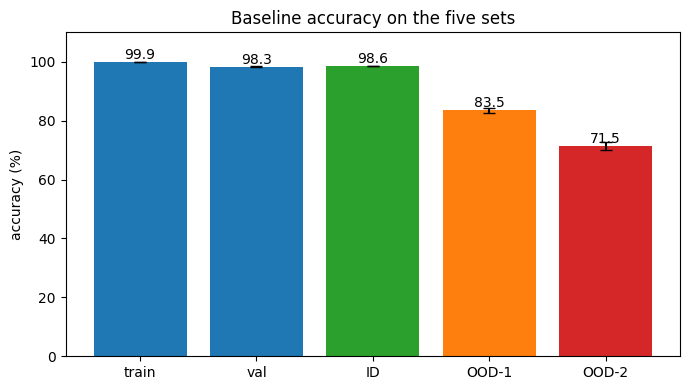

In [5]:
# ---------------- وظیفه ۲: ارزیابی ID و OOD (جدول ۱) ----------------
def agg(method, key, src=None):
    src = RES if src is None else src
    v = np.array([src[method][s][key] for s in SEEDS]) * 100
    return v.mean(), (v.std(ddof=1) if len(v) > 1 else 0.0)

rows = []
for k in ['train', 'val', 'id', 'ood1', 'ood2']:
    m, sd = agg('Baseline', k)
    rows.append({'مجموعه': SET_INFO[k][0], 'ρ': SET_INFO[k][1], 'دقت % (mean±std)': f"{m:.2f} ± {sd:.2f}"})
for k, nm in [('id_aligned', 'تست ID – رنگ هم‌جهت با شکل'), ('id_conflict', 'تست ID – رنگ مخالف شکل')]:
    m, sd = agg('Baseline', k)
    rows.append({'مجموعه': nm, 'ρ': '-', 'دقت % (mean±std)': f"{m:.2f} ± {sd:.2f}"})
T1 = pd.DataFrame(rows); T1.to_csv(f"{OUT}/table1_baseline_eval.csv", index=False, encoding='utf-8-sig')
display(T1)

fig, ax = plt.subplots(figsize=(7, 4))
keys = ['train', 'val', 'id', 'ood1', 'ood2']
mm = [agg('Baseline', k)[0] for k in keys]; ss = [agg('Baseline', k)[1] for k in keys]
ax.bar(['train', 'val', 'ID', 'OOD-1', 'OOD-2'], mm, yerr=ss, capsize=4, color=['C0', 'C0', 'C2', 'C1', 'C3'])
for i, v in enumerate(mm): ax.text(i, v + 1, f"{v:.1f}", ha='center')
ax.set_ylabel('accuracy (%)'); ax.set_ylim(0, 110); ax.set_title('Baseline accuracy on the five sets')
plt.tight_layout(); plt.savefig(f"{OUT}/fig2_baseline_accuracy.png", dpi=150); plt.show()

## وظیفه ۳: تشخیص نشانه (جدول ۲ و ۲ب)

In [6]:
# ---------------- وظیفه ۳: تشخیص نشانه ----------------
# ۳.۱ آزمون‌های Counterfactual:  تست A (تعویض رنگ)  و  تست B (حذف رنگ)
def swap_rg(x):    return x[:, [1, 0, 2]]                                    # قرمز↔سبز
def gray_mean(x):  return x.mean(1, keepdim=True).expand(-1, 3, -1, -1).clone()   # طبق صورت پروژه (شدت ۱/۳ می‌شود)
def gray_sum(x):   return x.sum(1, keepdim=True).expand(-1, 3, -1, -1).clone()    # کنترل: حذف رنگ با حفظ شدت

# ۳.۴ تغییر نشانه شکل (Misspecification)
def rot90(x):         return torch.rot90(x, 1, dims=(2, 3))
def occlude_top(x):
    x = x.clone(); x[:, :, :14, :] = 0; return x                              # حذف نیمه بالایی رقم
def patch_shuffle(x, p=7):
    B, C, H, W = x.shape; g = H // p
    pt  = x.unfold(2, p, p).unfold(3, p, p)                                   # (B,C,g,g,p,p)
    pt  = pt.reshape(B, C, g * g, p, p).permute(0, 2, 1, 3, 4)                 # (B,n,C,p,p)
    prm = torch.argsort(torch.rand(B, g * g, device=x.device), dim=1)
    pt  = pt[torch.arange(B, device=x.device)[:, None], prm]                  # جابه‌جایی تصادفی قطعه‌ها
    return pt.reshape(B, g, g, C, p, p).permute(0, 3, 1, 4, 2, 5).reshape(B, C, H, W)

def probe(model, x, y, c_shown):
    """acc: دقت ۱۰ کلاسه | half_acc: دقت تشخیص نیمه‌ی کلاس (0-4 یا 5-9)
    follow: نرخ پیروی از رنگ = درصد پیش‌بینی‌هایی که نیمه‌ی کلاسشان با نیمه‌ی القاشده توسط رنگ نمایش‌داده‌شده یکی است."""
    p = predict(model, x)
    return {'acc':      (p == y).float().mean().item(),
            'half_acc': ((p >= 5).long() == (y >= 5).long()).float().mean().item(),
            'follow':   ((p >= 5).long() == c_shown).float().mean().item()}

g_sub = torch.Generator().manual_seed(7)
SUB   = torch.randperm(len(S['id']), generator=g_sub)[:1000].to(DEVICE)      # ۱۰۰۰ نمونه تست برای تست Misspecification

def cue_suite(model):
    d, o = S['id'], {}
    o['original']        = probe(model, d.x, d.y, d.c)
    o['A_swap']          = probe(model, swap_rg(d.x),   d.y, 1 - d.c)
    o['B_gray_mean']     = probe(model, gray_mean(d.x), d.y, d.c)
    o['B_gray_sum']      = probe(model, gray_sum(d.x),  d.y, d.c)
    xs, ys, cs = d.x[SUB], d.y[SUB], d.c[SUB]
    torch.manual_seed(1234)
    o['M_orig']          = probe(model, xs, ys, cs)
    o['M_shape_rot90']   = probe(model, rot90(xs), ys, cs)
    o['M_shape_occlude'] = probe(model, occlude_top(xs), ys, cs)
    o['M_shape_shuffle'] = probe(model, patch_shuffle(xs), ys, cs)
    o['M_color_swap']    = probe(model, swap_rg(xs), ys, 1 - cs)
    o['M_color_gray']    = probe(model, gray_sum(xs), ys, cs)
    return o

for s in SEEDS:
    CUE.setdefault('Baseline', {})[s] = cue_suite(MODELS['Baseline'][s])

def cagg(method, probe_name, key):
    v = np.array([CUE[method][s][probe_name][key] for s in SEEDS]) * 100
    return v.mean(), (v.std(ddof=1) if len(v) > 1 else 0.0)

LABELS = [('original', 'تست ID اصلی (مرجع)'), ('A_swap', 'تست A: تعویض رنگ'),
          ('B_gray_mean', 'تست B: Grayscale (میانگین کانال‌ها، طبق صورت پروژه)'),
          ('B_gray_sum', 'تست B′: Grayscale با حفظ شدت (کنترل)')]
rows = []
for k, nm in LABELS:
    m, sd = cagg('Baseline', k, 'acc'); f, _ = cagg('Baseline', k, 'follow')
    rows.append({'تست': nm, 'دقت %': f"{m:.2f} ± {sd:.2f}", 'نرخ پیروی از رنگ %': f"{f:.1f}"})
T2 = pd.DataFrame(rows); T2.to_csv(f"{OUT}/table2_counterfactual.csv", index=False, encoding='utf-8-sig'); display(T2)

LABELS_M = [('M_orig', 'بدون تغییر (۱۰۰۰ نمونه)'), ('M_shape_rot90', 'تغییر شکل: چرخش ۹۰°'),
            ('M_shape_occlude', 'تغییر شکل: حذف نیمه بالایی'), ('M_shape_shuffle', 'تغییر شکل: بُر زدن قطعه‌ها'),
            ('M_color_swap', 'تغییر رنگ: تعویض'), ('M_color_gray', 'تغییر رنگ: حذف (حفظ شدت)')]
rows = []
for k, nm in LABELS_M:
    a, sd = cagg('Baseline', k, 'acc'); h_, _ = cagg('Baseline', k, 'half_acc'); f, _ = cagg('Baseline', k, 'follow')
    rows.append({'آزمون': nm, 'دقت ۱۰ کلاسه %': f"{a:.2f} ± {sd:.2f}", 'دقت نیمه‌کلاس %': f"{h_:.1f}", 'نرخ پیروی از رنگ %': f"{f:.1f}"})
T2b = pd.DataFrame(rows); T2b.to_csv(f"{OUT}/table2b_misspecification.csv", index=False, encoding='utf-8-sig'); display(T2b)
save_results()

,تست,دقت %,نرخ پیروی از رنگ %
0,تست ID اصلی (مرجع),98.55 ± 0.06,99.1
1,تست A: تعویض رنگ,68.42 ± 1.57,30.7
2,تست B: Grayscale (میانگین کانال‌ها، طبق صورت پ...,94.77 ± 0.09,95.4
3,تست B′: Grayscale با حفظ شدت (کنترل),94.50 ± 0.20,95.2


,آزمون,دقت ۱۰ کلاسه %,دقت نیمه‌کلاس %,نرخ پیروی از رنگ %
0,بدون تغییر (۱۰۰۰ نمونه),98.20 ± 0.20,99.6,99.2
1,تغییر شکل: چرخش ۹۰°,17.37 ± 2.45,95.2,95.8
2,تغییر شکل: حذف نیمه بالایی,63.77 ± 3.98,93.7,94.2
3,تغییر شکل: بُر زدن قطعه‌ها,20.33 ± 0.64,91.7,92.3
4,تغییر رنگ: تعویض,67.07 ± 2.24,69.1,31.6
5,تغییر رنگ: حذف (حفظ شدت),93.57 ± 0.32,95.2,94.5


### Saliency Map (Gradient × Input و گرادیان کانال‌ها)

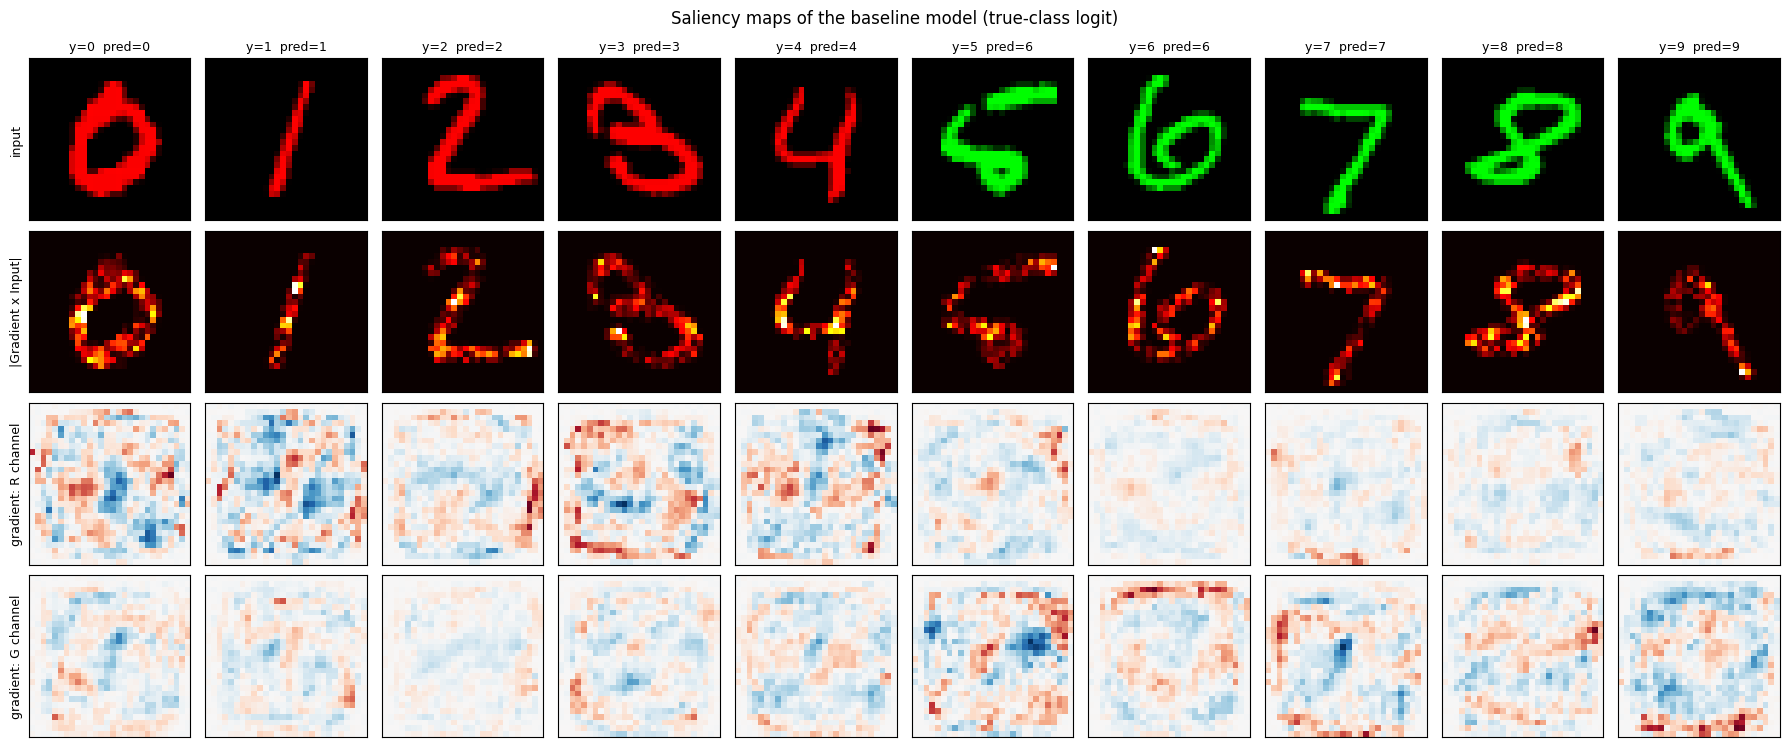

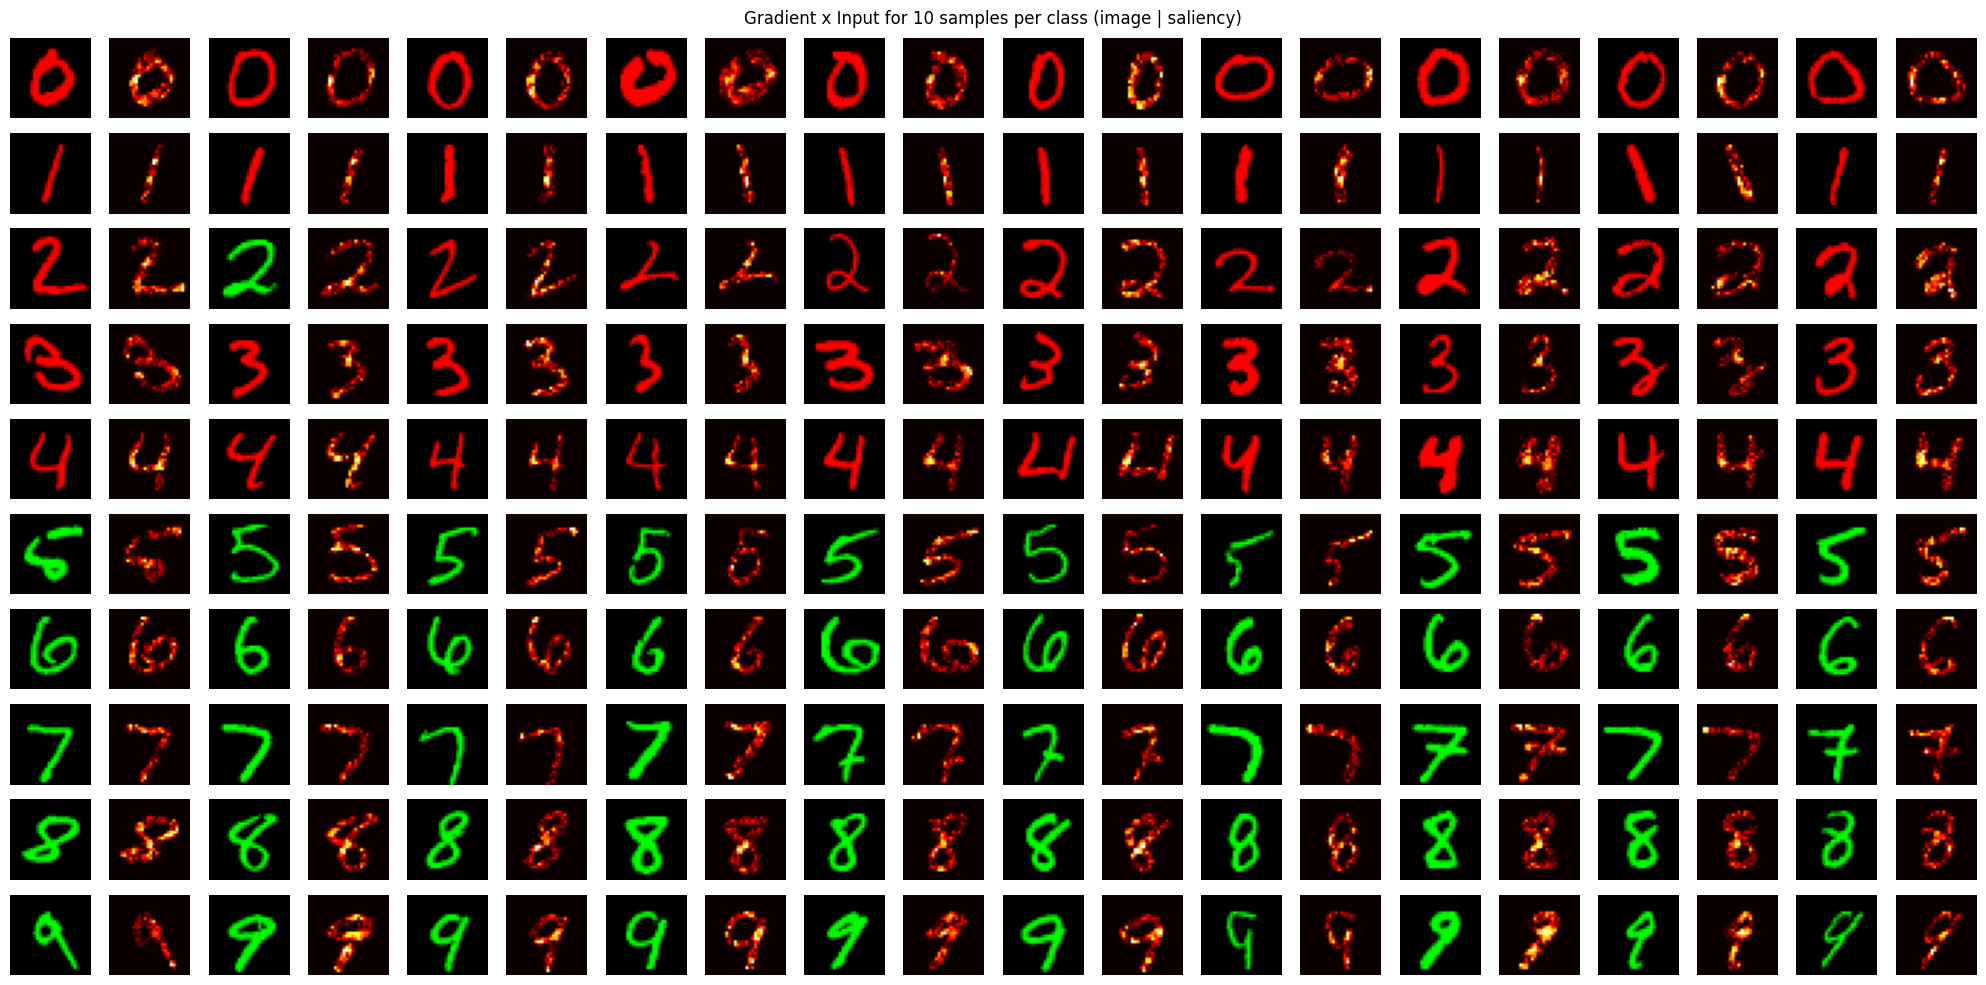

In [7]:
# ۳.۲ Saliency Map  (Gradient × Input) + گرادیان خام به تفکیک کانال رنگ
def attributions(model, x, target):
    model.eval()
    x = x.clone().requires_grad_(True)
    score = model(x).gather(1, target[:, None]).sum()
    grad, = torch.autograd.grad(score, x)
    return grad.detach(), (grad * x).detach()

base_model = MODELS['Baseline'][SEEDS[0]]
d = S['id']
idx10 = [torch.nonzero(d.y == k)[0, 0].item() for k in range(10)]            # یک نمونه از هر کلاس
x, y  = d.x[idx10], d.y[idx10]
g, gxi = attributions(base_model, x, y)
pred = predict(base_model, x)

fig, axes = plt.subplots(4, 10, figsize=(18, 7.6))
for j in range(10):
    axes[0, j].imshow(x[j].permute(1, 2, 0).cpu().numpy())
    axes[0, j].set_title(f"y={y[j].item()}  pred={pred[j].item()}", fontsize=9)
    axes[1, j].imshow(gxi[j].abs().sum(0).cpu().numpy(), cmap='hot')
    v = g[j].abs().max().item() + 1e-12
    axes[2, j].imshow(g[j, 0].cpu().numpy(), cmap='RdBu_r', vmin=-v, vmax=v)
    axes[3, j].imshow(g[j, 1].cpu().numpy(), cmap='RdBu_r', vmin=-v, vmax=v)
    for r in range(4): axes[r, j].set_xticks([]); axes[r, j].set_yticks([])
for r, t in enumerate(['input', '|Gradient x Input|', 'gradient: R channel', 'gradient: G channel']):
    axes[r, 0].set_ylabel(t, fontsize=9)
plt.suptitle("Saliency maps of the baseline model (true-class logit)"); plt.tight_layout()
plt.savefig(f"{OUT}/fig3_saliency.png", dpi=150); plt.show()

# شکل کامل: ۱۰ نمونه از هر کلاس (تصویر + Saliency)
fig, axes = plt.subplots(10, 20, figsize=(20, 10))
for k in range(10):
    ids = torch.nonzero(d.y == k)[:10, 0]
    gk, gxik = attributions(base_model, d.x[ids], d.y[ids])
    for j in range(10):
        axes[k, 2*j].imshow(d.x[ids[j]].permute(1, 2, 0).cpu().numpy())
        axes[k, 2*j+1].imshow(gxik[j].abs().sum(0).cpu().numpy(), cmap='hot')
        axes[k, 2*j].axis('off'); axes[k, 2*j+1].axis('off')
plt.suptitle("Gradient x Input for 10 samples per class (image | saliency)"); plt.tight_layout()
plt.savefig(f"{OUT}/fig3b_saliency_100samples.png", dpi=110); plt.show()

## وظیفه ۴: پنج روش کاهش سوگیری

In [8]:
# ---------------- وظیفه ۴: روش‌های کاهش سوگیری (هر پنج روش) ----------------
# روش ۱: Data Augmentation — ۱۰٪ نمونه بدون سوگیری (ρ=0.5) از ارقام «آموزش» ساخته و اضافه می‌شود
n_aug   = int(AUG_FRAC * len(S['train']))
aug_sel = np.random.RandomState(100).choice(len(tr_idx), n_aug, replace=False)
g_aug, y_aug = G_tr[tr_idx][aug_sel], Y_tr[tr_idx][aug_sel]
S_aug = CData(np.concatenate([G_tr[tr_idx], g_aug]),
              np.concatenate([Y_tr[tr_idx], y_aug]),
              np.concatenate([make_colors(Y_tr[tr_idx], RHO_TRAIN, 42), make_colors(y_aug, 0.5, 47)]))
print("augmented train size:", len(S_aug), "| aligned fraction: %.3f" % S_aug.aligned.float().mean().item())

# روش ۲: Reweighting — w_i = 1 / P(color=c_i | shape=s_i)، با برآورد تجربی P از داده آموزش
def reweight_weights(tr):
    w = torch.zeros(len(tr), device=DEVICE)
    for hf in (0, 1):
        for c in (0, 1):
            m = (tr.half == hf) & (tr.c == c)
            p = m.sum().item() / (tr.half == hf).sum().item()
            w[m] = 1.0 / p
    return w / w.mean()                                   # نرمال‌سازی: میانگین وزن = ۱
W_RW = reweight_weights(S['train'])
print("reweighting: weight(aligned)=%.3f  weight(conflicting)=%.3f" %
      (W_RW[S['train'].aligned][0].item(), W_RW[~S['train'].aligned][0].item()))

# روش ۳: Group DRO — کمینه‌سازی بدترین خطای گروهی با وزن‌های q_g (به‌روزرسانی نمایی)
def fit_group_dro(tr, seed, eta=DRO_ETA, epochs=EPOCHS):
    set_seed(seed)
    model = Net().to(DEVICE); opt = torch.optim.Adam(model.parameters(), lr=LR)
    q = torch.ones(4, device=DEVICE) / 4
    h, N = new_hist(), len(tr)
    for ep in range(epochs):
        model.train(); perm = torch.randperm(N, device=DEVICE)
        run, nb = torch.zeros((), device=DEVICE), 0
        for i in range(0, N, BATCH):
            idx = perm[i:i+BATCH]
            ce  = F.cross_entropy(model(tr.x[idx]), tr.y[idx], reduction='none')
            oh  = F.one_hot(tr.g[idx], 4).float()                    # (B,4)
            cnt = oh.sum(0)
            gl  = (oh * ce[:, None]).sum(0) / cnt.clamp_min(1)       # میانگین خطا در هر گروه (گروه غایب → 0)
            q   = q * torch.exp(eta * gl.detach())                   # گروه غایب: exp(0)=1
            q   = q / q.sum()
            loss = (q * gl).sum()
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
            run += loss.detach(); nb += 1
        log_epoch(h, model, (run / nb).item(), 'GroupDRO', ep)
    h['q_final'] = q.tolist()
    return model, h

# روش ۴: Learning from Failure — مدل سوگیرانه با GCE + مدل نهایی با وزن W = CE_B / (CE_B + CE_D)
def fit_lff(tr, seed, q=GCE_Q, alpha=EMA_ALPHA, epochs=EPOCHS):
    set_seed(seed)
    mb, md = Net().to(DEVICE), Net().to(DEVICE)
    opt = torch.optim.Adam(list(mb.parameters()) + list(md.parameters()), lr=LR)
    N = len(tr); h = new_hist()
    ema_b, ema_d = torch.zeros(N, device=DEVICE), torch.zeros(N, device=DEVICE)
    for ep in range(epochs):
        mb.train(); md.train(); perm = torch.randperm(N, device=DEVICE)
        run, nb = torch.zeros((), device=DEVICE), 0
        for i in range(0, N, BATCH):
            idx = perm[i:i+BATCH]; x, y = tr.x[idx], tr.y[idx]
            lb, ld = mb(x), md(x)
            ce_b = F.cross_entropy(lb, y, reduction='none'); ce_d = F.cross_entropy(ld, y, reduction='none')
            ema_b[idx] = alpha * ema_b[idx] + (1 - alpha) * ce_b.detach()       # EMA خطای هر نمونه
            ema_d[idx] = alpha * ema_d[idx] + (1 - alpha) * ce_d.detach()
            mx_b = torch.zeros(10, device=DEVICE).scatter_reduce(0, tr.y, ema_b, reduce='amax', include_self=True)
            mx_d = torch.zeros(10, device=DEVICE).scatter_reduce(0, tr.y, ema_d, reduce='amax', include_self=True)
            nb_  = ema_b[idx] / mx_b[y].clamp_min(1e-8)                          # نرمال‌سازی بر اساس بیشینه کلاس
            nd_  = ema_d[idx] / mx_d[y].clamp_min(1e-8)
            w    = nb_ / (nb_ + nd_ + 1e-8)                                      # نمونه‌های «سخت برای مدل سوگیرانه» وزن بیشتر
            p_y  = F.softmax(lb, 1).gather(1, y[:, None]).squeeze(1).clamp_min(1e-8)
            gce  = (1 - p_y ** q) / q                                            # Generalized CE
            loss = gce.mean() + (w.detach() * ce_d).mean()
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
            run += loss.detach(); nb += 1
        log_epoch(h, md, (run / nb).item(), 'LfF', ep)                           # مدل نهایی = مدل بی‌سوگیری md
    return md, h

# روش ۵: IRM — دو محیط با ρ=0.9 و ρ=0.5 (نیمی از ارقام آموزش در هر محیط) و جریمه IRMv1
n_half = len(tr_idx) // 2
ENVS = [make_cmnist(G_tr[tr_idx[:n_half]], Y_tr[tr_idx[:n_half]], RHO_TRAIN, 48),
        make_cmnist(G_tr[tr_idx[n_half:]], Y_tr[tr_idx[n_half:]], 0.5, 49)]

def fit_irm(envs, seed, lam=IRM_LAMBDA, anneal=IRM_ANNEAL, epochs=EPOCHS):
    set_seed(seed)
    model = Net().to(DEVICE); opt = torch.optim.Adam(model.parameters(), lr=LR)
    h = new_hist(); n_steps = math.ceil(min(len(e) for e in envs) / BATCH)
    for ep in range(epochs):
        model.train(); perms = [torch.randperm(len(e), device=DEVICE) for e in envs]
        run = torch.zeros((), device=DEVICE)
        for s in range(n_steps):
            risks, pens = [], []
            for e, pm in zip(envs, perms):
                idx   = pm[s*BATCH:(s+1)*BATCH]
                scale = torch.tensor(1.0, device=DEVICE, requires_grad=True)       # w=1 در IRMv1
                risk  = F.cross_entropy(model(e.x[idx]) * scale, e.y[idx])
                gw,   = torch.autograd.grad(risk, [scale], create_graph=True)
                risks.append(risk); pens.append(gw ** 2)
            erm, pen = torch.stack(risks).mean(), torch.stack(pens).mean()
            wt   = lam if ep >= anneal else 1.0
            loss = erm + wt * pen
            if wt > 1.0: loss = loss / wt                                           # حفظ مقیاس گرادیان (مثل کد IRM)
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
            run += loss.detach()
        log_epoch(h, model, (run / n_steps).item(), 'IRM', ep)
    return model, h

METHODS = {
    'M1_Augmentation': lambda s: fit_erm(S_aug, s, tag='Aug'),
    'M2_Reweighting':  lambda s: fit_erm(S['train'], s, sample_w=W_RW, tag='Reweight'),
    'M3_GroupDRO':     lambda s: fit_group_dro(S['train'], s),
    'M4_LfF':          lambda s: fit_lff(S['train'], s),
    'M5_IRM':          lambda s: fit_irm(ENVS, s),
}

augmented train size: 55000 | aligned fraction: 0.945
reweighting: weight(aligned)=0.505  weight(conflicting)=49.299


In [9]:
# ---------------- اجرای همه روش‌ها روی همه seedها ----------------
for name, fn in METHODS.items():
    t0 = time.time()
    for s in SEEDS:
        m, h = fn(s)
        register(name, s, m, h)
        CUE.setdefault(name, {})[s] = cue_suite(m)
    print(f"##### {name} done in {time.time()-t0:.0f}s\n")
    torch.save({s: MODELS[name][s].state_dict() for s in SEEDS}, f"{OUT}/{name}_weights.pth")
    save_results()
CUE['Baseline'] = {s: cue_suite(MODELS['Baseline'][s]) for s in SEEDS}
save_results()

  [Aug] epoch  1  obj=0.2823  train_acc=0.9678  val_acc=0.9598  ood1=0.8347  ood2=0.7318
  [Aug] epoch  5  obj=0.0518  train_acc=0.9926  val_acc=0.9813  ood1=0.9291  ood2=0.8868
  [Aug] epoch 10  obj=0.0200  train_acc=0.9982  val_acc=0.9836  ood1=0.9441  ood2=0.9113
  [Aug] epoch 15  obj=0.0123  train_acc=0.9995  val_acc=0.9853  ood1=0.9379  ood2=0.8991
  [Aug] epoch 20  obj=0.0098  train_acc=0.9993  val_acc=0.9855  ood1=0.9413  ood2=0.9013
==> M1_Augmentation seed=0: ID=0.9858 OOD1=0.9413 OOD2=0.9013
  [Aug] epoch  1  obj=0.2823  train_acc=0.9654  val_acc=0.9591  ood1=0.8379  ood2=0.7358
  [Aug] epoch  5  obj=0.0549  train_acc=0.9923  val_acc=0.9809  ood1=0.9208  ood2=0.8705
  [Aug] epoch 10  obj=0.0213  train_acc=0.9974  val_acc=0.9844  ood1=0.9310  ood2=0.8841
  [Aug] epoch 15  obj=0.0113  train_acc=0.9992  val_acc=0.9847  ood1=0.9412  ood2=0.9050
  [Aug] epoch 20  obj=0.0090  train_acc=0.9988  val_acc=0.9833  ood1=0.9417  ood2=0.9080
==> M1_Augmentation seed=1: ID=0.9861 OOD1=0.941

### جدول ۳ و ۴ و نمودارها

,روش,دقت ID %,دقت OOD-1 %,دقت OOD-2 %,اختلاف ID−OOD1,اختلاف ID−OOD2
0,Baseline,98.55 ± 0.06,83.53 ± 0.82,71.48 ± 1.36,15.02 ± 0.77,27.07 ± 1.30
1,M1_Augmentation,98.61 ± 0.03,94.07 ± 0.14,90.38 ± 0.36,4.54 ± 0.16,8.23 ± 0.36
2,M2_Reweighting,98.42 ± 0.20,87.88 ± 0.76,79.88 ± 1.05,10.54 ± 0.56,18.54 ± 0.85
3,M3_GroupDRO,98.61 ± 0.05,85.70 ± 0.44,75.87 ± 0.87,12.91 ± 0.49,22.74 ± 0.90
4,M4_LfF,90.70 ± 0.70,85.90 ± 0.90,81.87 ± 1.48,4.80 ± 0.85,8.83 ± 1.64
5,M5_IRM,96.63 ± 0.38,94.14 ± 1.00,91.86 ± 1.74,2.49 ± 0.95,4.77 ± 1.70


,روش,دقت پس از تعویض رنگ %,دقت Grayscale (حفظ شدت) %,نرخ پیروی از رنگ پس از بُر زدن شکل %
0,Baseline,68.4,94.5,92.3
1,M1_Augmentation,89.4,96.6,77.2
2,M2_Reweighting,77.6,95.2,68.4
3,M3_GroupDRO,73.2,95.0,96.0
4,M4_LfF,80.9,92.0,89.7
5,M5_IRM,91.4,95.6,59.5


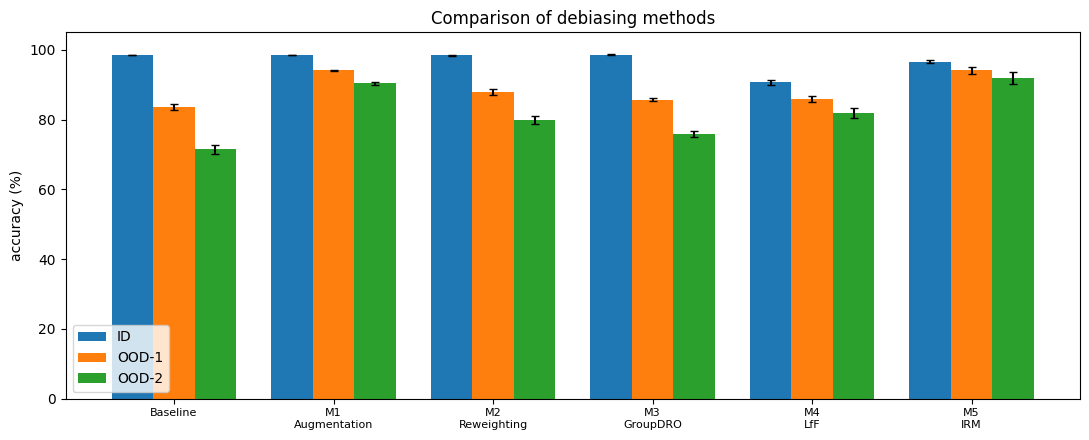

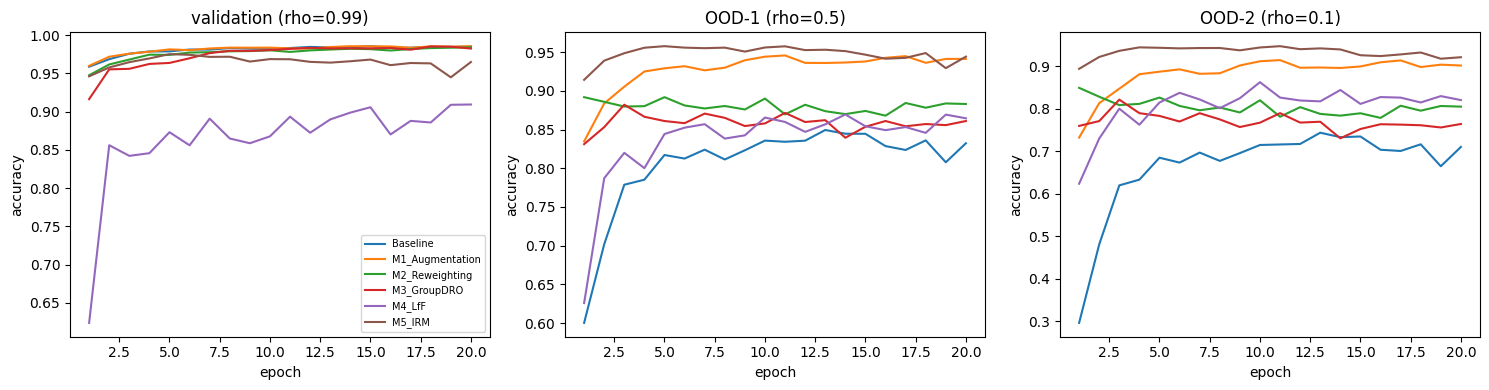

In [10]:
# ---------------- جدول ۳: مقایسه روش‌ها ----------------
ORDER = ['Baseline'] + list(METHODS.keys())
def gap_stat(method, ood):
    v = np.array([RES[method][s]['id'] - RES[method][s][ood] for s in SEEDS]) * 100
    return v.mean(), (v.std(ddof=1) if len(v) > 1 else 0.0)

rows = []
for mth in ORDER:
    r = {'روش': mth}
    for k, nm in [('id', 'ID'), ('ood1', 'OOD-1'), ('ood2', 'OOD-2')]:
        m, sd = agg(mth, k); r[f'دقت {nm} %'] = f"{m:.2f} ± {sd:.2f}"
    for ood, nm in [('ood1', 'ID−OOD1'), ('ood2', 'ID−OOD2')]:
        m, sd = gap_stat(mth, ood); r[f'اختلاف {nm}'] = f"{m:.2f} ± {sd:.2f}"
    rows.append(r)
T3 = pd.DataFrame(rows); T3.to_csv(f"{OUT}/table3_methods.csv", index=False, encoding='utf-8-sig'); display(T3)

# جدول ۴ (تکمیلی): پروفایل «تکیه بر رنگ» برای همه روش‌ها
rows = []
for mth in ORDER:
    a, _ = cagg(mth, 'A_swap', 'acc'); b, _ = cagg(mth, 'B_gray_sum', 'acc'); f, _ = cagg(mth, 'M_shape_shuffle', 'follow')
    rows.append({'روش': mth, 'دقت پس از تعویض رنگ %': f"{a:.1f}", 'دقت Grayscale (حفظ شدت) %': f"{b:.1f}",
                 'نرخ پیروی از رنگ پس از بُر زدن شکل %': f"{f:.1f}"})
T4 = pd.DataFrame(rows); T4.to_csv(f"{OUT}/table4_cue_profile.csv", index=False, encoding='utf-8-sig'); display(T4)

# نمودار مقایسه‌ای
fig, ax = plt.subplots(figsize=(11, 4.5)); wd = 0.26; xs_ = np.arange(len(ORDER))
for j, (k, nm) in enumerate([('id', 'ID'), ('ood1', 'OOD-1'), ('ood2', 'OOD-2')]):
    ax.bar(xs_ + (j - 1) * wd, [agg(m_, k)[0] for m_ in ORDER], wd, yerr=[agg(m_, k)[1] for m_ in ORDER], capsize=3, label=nm)
ax.set_xticks(xs_); ax.set_xticklabels([m_.replace('_', '\n') for m_ in ORDER], fontsize=8)
ax.set_ylabel('accuracy (%)'); ax.set_ylim(0, 105); ax.legend(); ax.set_title('Comparison of debiasing methods')
plt.tight_layout(); plt.savefig(f"{OUT}/fig5_methods_comparison.png", dpi=150); plt.show()

# پویایی یادگیری (seed اول)
fig, ax = plt.subplots(1, 3, figsize=(15, 4)); s0 = SEEDS[0]
for j, (k, nm) in enumerate([('val_acc', 'validation (rho=0.99)'), ('ood1_acc', 'OOD-1 (rho=0.5)'), ('ood2_acc', 'OOD-2 (rho=0.1)')]):
    for mth in ORDER: ax[j].plot(range(1, EPOCHS + 1), HIST[mth][s0][k], label=mth)
    ax[j].set_title(nm); ax[j].set_xlabel('epoch'); ax[j].set_ylabel('accuracy')
ax[0].legend(fontsize=7); plt.tight_layout(); plt.savefig(f"{OUT}/fig6_training_dynamics.png", dpi=150); plt.show()
save_results()

### مقایسه MLP و CNN (اختیاری)

In [11]:
# مقایسه MLP و CNN: فایل results.json نسخه CNN را در Colab آپلود کنید (مسیر پایین را تنظیم کنید)
CNN_JSON = "results/results.json"
if os.path.exists(CNN_JSON):
    J = json.load(open(CNN_JSON, encoding='utf-8'))
    sc = [str(s) for s in J['cfg']['SEEDS']]
    print("CNN file: RHO_TRAIN =", J['cfg'].get('RHO_TRAIN', 0.9), "| arch:", J['cfg'].get('ARCH_FA', 'SimpleCNN سه‌لایه'))
    cnn = [np.mean([J['RES']['Baseline'][s][k] for s in sc]) * 100 for k in ('id', 'ood1', 'ood2')]
    mlp = [agg('Baseline', k)[0] for k in ('id', 'ood1', 'ood2')]
    fig, ax = plt.subplots(figsize=(7, 4)); xs_ = np.arange(3)
    ax.bar(xs_ - 0.2, cnn, 0.4, label='CNN'); ax.bar(xs_ + 0.2, mlp, 0.4, label='MLP')
    for i in range(3): ax.text(i - 0.2, cnn[i] + 0.5, f"{cnn[i]:.1f}", ha='center'); ax.text(i + 0.2, mlp[i] + 0.5, f"{mlp[i]:.1f}", ha='center')
    ax.set_xticks(xs_); ax.set_xticklabels(['ID', 'OOD-1', 'OOD-2']); ax.set_ylabel('accuracy (%)'); ax.legend()
    ax.set_title('Baseline: CNN vs MLP (mean over seeds)'); plt.tight_layout()
    plt.savefig(f"{OUT}/fig_architecture_comparison.png", dpi=150); plt.show()
else:
    print("results.json مربوط به CNN پیدا نشد؛ مقایسه رد شد.")

results.json مربوط به CNN پیدا نشد؛ مقایسه رد شد.


In [12]:
import shutil
shutil.make_archive('project_mlp_rho99', 'zip', OUT)
try:
    from google.colab import files
    files.download('project_mlp_rho99.zip')
except Exception:
    print('zip saved: project_mlp_rho99.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>